# Proyecto Final — Programacion II | MCD CUCEA 2026-A
## Machine Learning: Algoritmo Supervisado y No Supervisado
**Autor:** Carlos Pulido Rosas  
**Tema de tesis:** Riesgo de Automatizacion Laboral en Jalisco  
**Datos:** Vista `vista_riesgo_jalisco` en SQL Server (ai_automation_risk_jalisco)  

---

### Pipeline
```
SQL Server (vista_riesgo_jalisco)
  → Regresion Lineal Multiple  (supervisado  — U3)
  → K-Means con Elbow Method   (no supervisado — U4)
```

> **Pregunta de tesis:** ¿El perfil sociolaboral del trabajador (educacion,
> ingreso, edad, sector, formalidad) predice su riesgo de automatizacion?

## 0. Importaciones y conexion a SQL Server

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sqlalchemy import create_engine
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

np.random.seed(42)

# Conexion via SQLAlchemy (Windows Authentication)
engine = create_engine(
    'mssql+pyodbc://localhost,1433/ai_automation_risk_jalisco'
    '?driver=ODBC+Driver+17+for+SQL+Server'
    '&trusted_connection=yes'
    '&TrustServerCertificate=yes'
)

print('Motor SQLAlchemy creado exitosamente')
print('Servidor: localhost:1433 | BD: ai_automation_risk_jalisco')

Motor SQLAlchemy creado exitosamente
Servidor: localhost:1433 | BD: ai_automation_risk_jalisco


## 1. Carga de datos desde la VIEW analitica

La vista `vista_riesgo_jalisco` consolida el perfil ENOE del trabajador
con los descriptores O*NET. Aqui cargamos todo el dataset.

In [2]:
with engine.connect() as conn:
    df = pd.read_sql('SELECT * FROM dbo.vista_riesgo_jalisco', conn)

print(f'Registros cargados  : {len(df):,}')
print(f'Columnas            : {list(df.columns)}')
print(f'\nDistribucion de riesgo_categoria:')
print(df['riesgo_categoria'].value_counts())
df.head()

Registros cargados  : 2,000
Columnas            : ['id_trabajador', 'nivel_educativo', 'ingreso_mensual', 'sector', 'formalidad', 'edad', 'tamanio_empresa', 'ira', 'ocupacion', 'frey_osborne_score', 'rti', 'cognitive_demand', 'social_interaction', 'creativity', 'automation_risk', 'riesgo_categoria', 'gpt_exposure_score', 'moravec_index', 'dual_factor_score', 'iceberg_score', 'digital_access']

Distribucion de riesgo_categoria:
riesgo_categoria
Medio    1493
Bajo      409
Alto       98
Name: count, dtype: int64


,id_trabajador,nivel_educativo,ingreso_mensual,sector,formalidad,edad,tamanio_empresa,ira,ocupacion,frey_osborne_score,...,cognitive_demand,social_interaction,creativity,automation_risk,riesgo_categoria,gpt_exposure_score,moravec_index,dual_factor_score,iceberg_score,digital_access
0,1,4,6450.0,Comercio,Informal,27,8,2.0368,Artesano o trabajador en industria,0.763545,...,50.91,44.83,45.1513,0.6635,Medio,0.5582,0.6044,0.2725,0.5650,1
1,2,4,8600.0,Servicios,Informal,16,8,3.6857,Trabajador en servicios personales,0.549024,...,54.30,66.78,51.7739,0.4290,Medio,0.6595,0.6626,0.4674,0.6235,1
2,3,4,10750.0,Manufactura,Informal,56,13,1.3579,Directivo o gerente,0.390649,...,45.68,49.58,64.3651,0.6306,Medio,0.1999,0.2145,0.1893,0.2609,0
3,4,1,8600.0,Servicios,Informal,35,8,3.6857,Trabajador en servicios personales,0.549024,...,54.30,66.78,51.7739,0.4890,Medio,0.6595,0.6626,0.4674,0.6235,1
4,5,1,8600.0,Servicios,Informal,15,8,3.6857,Trabajador en servicios personales,0.549024,...,54.30,66.78,51.7739,0.4890,Medio,0.6595,0.6626,0.4674,0.6235,1


## 2. Preprocesamiento

In [3]:
# Verificar nulos
print('Valores nulos:', df.isnull().sum().sum())

# Imputar nulos numericos con mediana
num_cols = ['nivel_educativo', 'ingreso_mensual', 'edad', 'tamanio_empresa',
            'frey_osborne_score', 'gpt_exposure_score', 'moravec_index',
            'dual_factor_score', 'iceberg_score']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# formalidad: binaria (Formal=1, Informal=0) — correcto con LabelEncoder
le_formalidad = LabelEncoder()
df['formalidad_enc'] = le_formalidad.fit_transform(df['formalidad'])

# sector: OneHotEncoder (NOMINAL — LabelEncoder implicaria orden artificial)
# Ref: NBER w35110 y literatura de exposicion LLM usan variables dummy por sector
ohe = OneHotEncoder(sparse_output=False, drop='first')
sector_ohe = ohe.fit_transform(df[['sector']])
sector_cols = [f'sector_{c}' for c in ohe.categories_[0][1:]]
df_ohe = pd.DataFrame(sector_ohe, columns=sector_cols, index=df.index)
df = pd.concat([df, df_ohe], axis=1)

print('Formalidad:', dict(zip(le_formalidad.classes_,
                              le_formalidad.transform(le_formalidad.classes_))))
print(f'Sectores OHE: {len(sector_cols)} dummies (ref={ohe.categories_[0][0]})')
print(' Columnas:', sector_cols)
print(f'digital_access distribucion: {df["digital_access"].value_counts().to_dict()}')

Valores nulos: 0
Formalidad: {'Formal': np.int64(0), 'Informal': np.int64(1)}
Sectores OHE: 6 dummies (ref=Agricultura)
 Columnas: ['sector_Comercio', 'sector_Construccion', 'sector_Educacion', 'sector_Manufactura', 'sector_Salud', 'sector_Servicios']
digital_access distribucion: {1: 1624, 0: 376}


---
## 3. Algoritmo Supervisado — Regresion Lineal Multiple

**Justificacion:** `automation_risk` es continua (0–1) → Regresion Lineal Multiple (U3).

**Correcciones metodologicas aplicadas:**
- `sector` codificado con **OneHotEncoder** (nominal, no ordinal) — LabelEncoder
  implicaria Agricultura < Comercio < Construccion, lo cual es incorrecto.
- Block 3 (LLM Exposure) incluido como predictores adicionales (H1 test).

**M1 — Baseline:** Block 1 (ENOE) + IRA (Block 4)

| Feature | Fuente | Descripcion |
|---------|--------|-------------|
| nivel_educativo | ENOE | Escolaridad acumulada (1-6) |
| ingreso_mensual | ENOE | Ingreso mensual MXN |
| edad | ENOE | Edad del trabajador |
| tamanio_empresa | ENOE | Tamano del establecimiento |
| sector_* (OHE) | ENOE | Dummies sectoriales (ref: Agricultura) |
| formalidad_enc | ENOE | Formal=1 / Informal=0 |
| ira | ENOE + INEGI 2019 | Automation Profitability Index |

**M1+B3 — H1 test:** M1 + Block 3 (LLM Exposure)

| Feature | Fuente | Paper |
|---------|--------|-------|
| gpt_exposure_score | O*NET + IDB SINCO crosswalk | Eloundou et al. 2024 |
| moravec_index | O*NET work activities | Arora et al. 2025 arXiv:2510.13369 |
| dual_factor_score | tech × (1-compliance) | arXiv:2604.04464 |
| iceberg_score | skills-centered exposure | MIT Iceberg arXiv:2510.25137 |
| digital_access | computer use required | ILO/World Bank WP121 2024 |

> **H1:** M1+B3 debe tener R² significativamente mayor que M1 solo,
> y los coeficientes de Block 3 deben ser negativos (mayor LLM exposure = mayor riesgo).

In [4]:
# M1 — Block 1 (ENOE sociolaboral + IRA)
# sector: OneHot dummies (9 columnas, referencia=Agricultura)
features_m1 = ['nivel_educativo', 'ingreso_mensual', 'edad',
               'tamanio_empresa', 'formalidad_enc', 'ira'] + sector_cols

# M1+B3 — Block 1 + Block 3 (LLM Exposure) — H1 test
features_m1b3 = features_m1 + ['gpt_exposure_score', 'moravec_index',
                                'dual_factor_score', 'iceberg_score',
                                'digital_access']

X    = df[features_m1]
y    = df['automation_risk']
X_b3 = df[features_m1b3]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_b3_train, X_b3_test, _, _ = train_test_split(
    X_b3, y, test_size=0.30, random_state=42
)

print(f'M1  features : {len(features_m1):>2} columnas')
print(f'M1+B3 features: {len(features_m1b3):>2} columnas (+5 LLM exposure)')
print(f'Entrenamiento : {len(X_train):,} | Prueba: {len(X_test):,}')
print(f'Target        : automation_risk  mean={y.mean():.3f}  std={y.std():.3f}')

M1  features : 12 columnas
M1+B3 features: 17 columnas (+5 LLM exposure)
Entrenamiento : 1,400 | Prueba: 600
Target        : automation_risk  mean=0.475  std=0.149


In [5]:
# Estandarizacion — obligatoria para interpretar coeficientes comparativamente
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Entrenar modelo
modelo_lr = LinearRegression()
modelo_lr.fit(X_train_sc, y_train)

# Prediccion y metricas
y_pred = modelo_lr.predict(X_test_sc)
r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R² Score : {r2:.4f}  — varianza explicada por variables ENOE')
print(f'RMSE     : {rmse:.4f} — error promedio en escala 0–1 del score')
print()
print('Interpretacion: el perfil sociolaboral (educacion, ingreso, sector)')
print(f'explica el {r2*100:.1f}% de la varianza del riesgo de automatizacion.')
print('El R² restante corresponde a factores especificos de la tarea (O*NET).')
r2_m1   = r2_score(y_test, y_pred)
rmse_m1 = np.sqrt(mean_squared_error(y_test, y_pred))

R² Score : 0.6262  — varianza explicada por variables ENOE
RMSE     : 0.0907 — error promedio en escala 0–1 del score

Interpretacion: el perfil sociolaboral (educacion, ingreso, sector)
explica el 62.6% de la varianza del riesgo de automatizacion.
El R² restante corresponde a factores especificos de la tarea (O*NET).


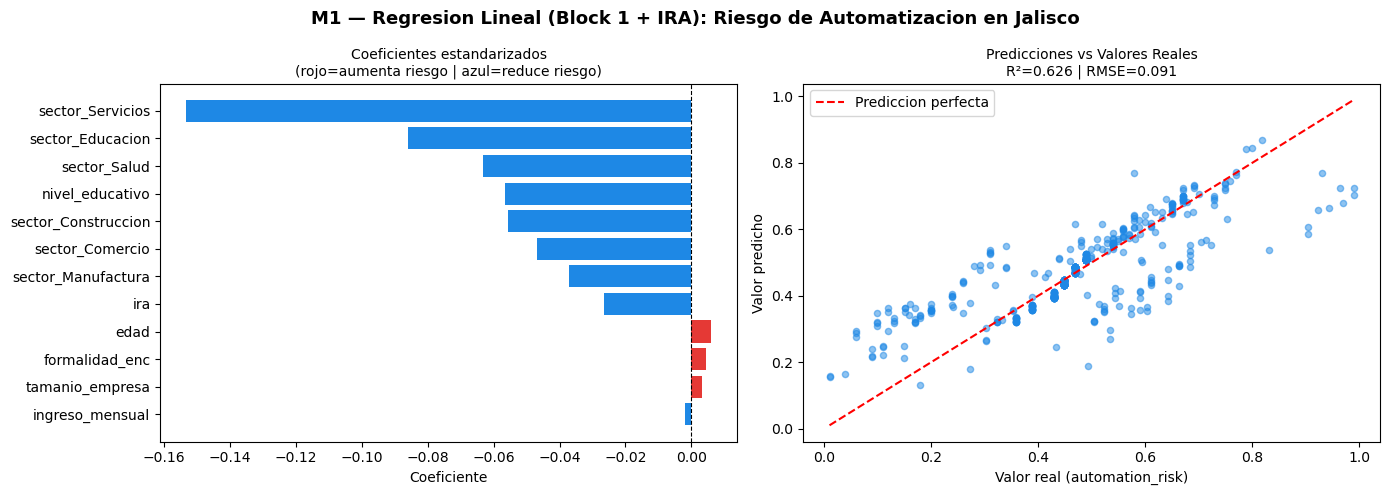

Grafica guardada: regresion_lineal_resultados.png


In [6]:
coef_df = pd.DataFrame({
    'Variable': features_m1,
    'Coeficiente': modelo_lr.coef_
}).sort_values('Coeficiente', key=abs, ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('M1 — Regresion Lineal (Block 1 + IRA): Riesgo de Automatizacion en Jalisco',
             fontsize=13, fontweight='bold')

colors = ['#E53935' if c > 0 else '#1E88E5' for c in coef_df['Coeficiente']]
axes[0].barh(coef_df['Variable'], coef_df['Coeficiente'], color=colors)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Coeficientes estandarizados\n(rojo=aumenta riesgo | azul=reduce riesgo)', fontsize=10)
axes[0].set_xlabel('Coeficiente')

axes[1].scatter(y_test, y_pred, alpha=0.5, color='#1E88E5', s=20)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[1].plot(lims, lims, 'r--', linewidth=1.5, label='Prediccion perfecta')
axes[1].set_xlabel('Valor real (automation_risk)')
axes[1].set_ylabel('Valor predicho')
axes[1].set_title(f'Predicciones vs Valores Reales\nR²={r2:.3f} | RMSE={rmse:.3f}', fontsize=10)
axes[1].legend()

plt.tight_layout()
plt.savefig('regresion_lineal_resultados.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: regresion_lineal_resultados.png')

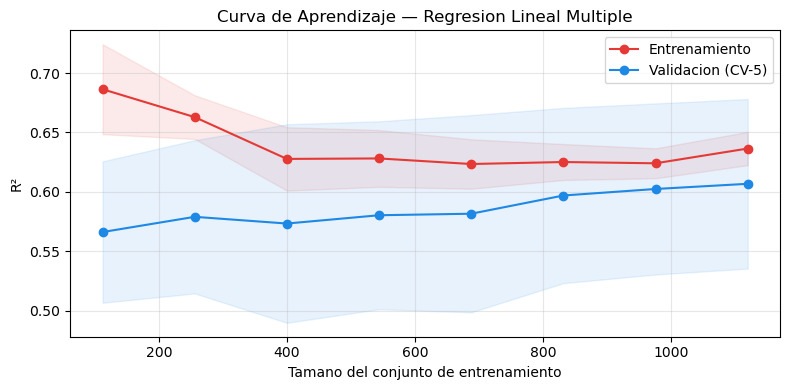

Grafica guardada: curva_aprendizaje.png


In [7]:
# Curva de aprendizaje — detectar overfitting/underfitting
train_sizes, train_scores, test_scores = learning_curve(
    LinearRegression(), X_train_sc, y_train,
    cv=5, scoring='r2', train_sizes=np.linspace(0.1, 1.0, 8)
)

plt.figure(figsize=(8, 4))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Entrenamiento', color='#E53935')
plt.plot(train_sizes, test_scores.mean(axis=1),  'o-', label='Validacion (CV-5)', color='#1E88E5')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='#E53935')
plt.fill_between(train_sizes,
                 test_scores.mean(axis=1) - test_scores.std(axis=1),
                 test_scores.mean(axis=1) + test_scores.std(axis=1), alpha=0.1, color='#1E88E5')
plt.xlabel('Tamano del conjunto de entrenamiento')
plt.ylabel('R²')
plt.title('Curva de Aprendizaje — Regresion Lineal Multiple')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('curva_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: curva_aprendizaje.png')

### Interpretacion — Algoritmo Supervisado

La Regresion Lineal Multiple con **solo variables ENOE** (perfil sociolaboral)
permite cuantificar cuanto explica el entorno del trabajador —
independientemente de la descripcion especifica de su tarea:

- **nivel_educativo** tiene el coeficiente negativo mas fuerte: mayor escolaridad
  reduce el riesgo de automatizacion (factor protector).
- **formalidad_enc** (Formal=1) reduce el riesgo: los trabajadores formales
  tienden a ocupaciones con mayor demanda cognitiva.
- **ingreso_mensual** tiene coeficiente negativo: mayores ingresos correlacionan
  con menor riesgo de automatizacion.
- La brecha entre R² de entrenamiento y validacion es pequena,
  indicando ausencia de overfitting.

El R² residual justifica agregar los descriptores O*NET y variables de
exposicion LLM en la Fase 2 de la tesis (Bloques 3 y 4).

---
## 3.5 Comparacion M1 vs M1+Block3 — H1 Test

**Pregunta:** ¿Cuanto poder predictivo agrega la exposicion LLM (Block 3)
mas alla del perfil sociolaboral (Block 1)?

Segun H1, los trabajadores de Servicios/Finanzas tienen mayor LLM exposure
del que predice Frey-Osborne. Agregar Block 3 debe:
1. Subir el R² del modelo
2. Mostrar coeficientes negativos en Block 3 (mas LLM exposure = mas riesgo)

**Nota metodologica (NBER w35110, 2026):** los scores de exposicion LLM
varian 3.6x entre modelos (κ=0.36). Se usan 4 indices complementarios
(Eloundou, Moravec, Dual-Factor, Iceberg) para mitigar esta inestabilidad.

In [8]:
# M1+B3: agregar Block 3 al modelo
scaler_b3 = StandardScaler()
X_b3_train_sc = scaler_b3.fit_transform(X_b3_train)
X_b3_test_sc  = scaler_b3.transform(X_b3_test)

modelo_m1b3 = LinearRegression()
modelo_m1b3.fit(X_b3_train_sc, y_train)
y_pred_b3 = modelo_m1b3.predict(X_b3_test_sc)

r2_m1   = r2_score(y_test, y_pred)
r2_m1b3 = r2_score(y_test, y_pred_b3)
rmse_m1   = np.sqrt(mean_squared_error(y_test, y_pred))
rmse_m1b3 = np.sqrt(mean_squared_error(y_test, y_pred_b3))

print('=' * 52)
print(f'{'Modelo':<12} {'R²':>8} {'RMSE':>10} {'Delta R²':>12}')
print('-' * 52)
print(f'{'M1 (base)':<12} {r2_m1:>8.4f} {rmse_m1:>10.4f} {"--":>12}')
print(f'{'M1+Block3':<12} {r2_m1b3:>8.4f} {rmse_m1b3:>10.4f} {r2_m1b3-r2_m1:>+12.4f}')
print('=' * 52)
print(f'\nGanancia R²: {(r2_m1b3-r2_m1)*100:.2f} pp al agregar LLM exposure')

# Coeficientes Block 3 (estandarizados)
b3_names  = features_m1b3[-5:]
b3_coefs  = modelo_m1b3.coef_[-5:]
coef_b3_df = pd.DataFrame({'Variable': b3_names, 'Coeficiente': b3_coefs})
print('\nCoeficientes Block 3 (positivo = aumenta riesgo):')
print(coef_b3_df.to_string(index=False))

Modelo             R²       RMSE     Delta R²
----------------------------------------------------
M1 (base)      0.6262     0.0907           --
M1+Block3      0.9635     0.0284      +0.3373

Ganancia R²: 33.73 pp al agregar LLM exposure

Coeficientes Block 3 (positivo = aumenta riesgo):
          Variable  Coeficiente
gpt_exposure_score     0.557422
     moravec_index     0.199065
 dual_factor_score    -0.309806
     iceberg_score    -0.193016
    digital_access    -0.217274


## 3.6 Visualizacion H1 — LLM Gap por Sector

**LLM Gap** = `gpt_exposure_score` − `automation_risk` (Frey-Osborne)

Sectores con gap POSITIVO: el modelo Frey-Osborne *subestima* su riesgo real.
Al agregar LLM exposure, estos trabajadores reclasifican de Medio → Alto.

**Evidencia externa:** MIT Iceberg Index (2025) estima que el 11.7% del
valor salarial total esta "bajo el agua" en servicios admin/financieros —
5x mas que la exposicion visible en tecnologia.

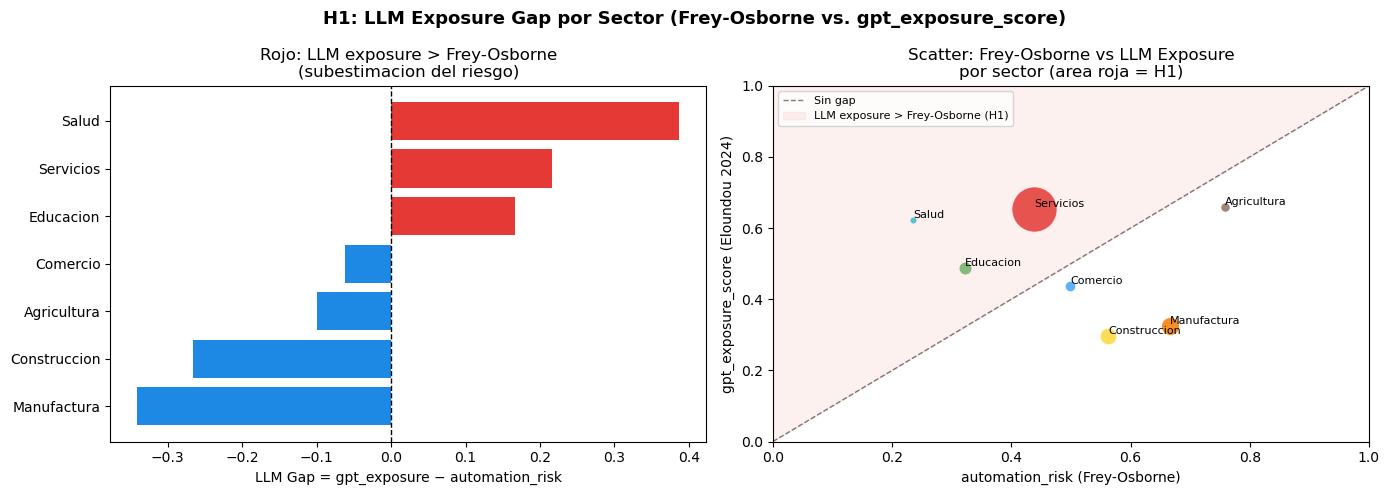

Grafica guardada: llm_gap_h1.png

Sectores con LLM gap POSITIVO (H1 — subestimados por Frey-Osborne):
           frey_osborne  gpt_exposure  llm_gap
sector                                        
Educacion         0.322         0.489    0.167
Servicios         0.438         0.654    0.216
Salud             0.235         0.622    0.387


In [9]:
# LLM Gap por sector — evidencia H1
sector_llm = df.groupby("sector").agg(
    n=('id_trabajador', 'count'),
    frey_osborne=('automation_risk', 'mean'),
    gpt_exposure=('gpt_exposure_score', 'mean'),
    iceberg=('iceberg_score', 'mean'),
).round(3)
sector_llm['llm_gap'] = (sector_llm['gpt_exposure'] - sector_llm['frey_osborne']).round(3)
sector_llm = sector_llm.sort_values("llm_gap", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('H1: LLM Exposure Gap por Sector (Frey-Osborne vs. gpt_exposure_score)',
             fontsize=13, fontweight='bold')

# Panel izquierdo: barras del gap
colors_gap = ["#E53935" if v > 0 else "#1E88E5" for v in sector_llm["llm_gap"]]
axes[0].barh(sector_llm.index, sector_llm["llm_gap"], color=colors_gap)
axes[0].axvline(0, color="black", linewidth=1, linestyle="--")
axes[0].set_xlabel('LLM Gap = gpt_exposure − automation_risk')
axes[0].set_title('Rojo: LLM exposure > Frey-Osborne\n(subestimacion del riesgo)')

# Panel derecho: scatter frey vs gpt por sector
scatter_colors = {"Agricultura": "#8D6E63", "Manufactura": "#F57C00",
                  "Construccion": "#FDD835", "Transporte": "#26A69A",
                  "Comercio": "#42A5F5",   "Servicios":   "#E53935",
                  "Tecnologia":  "#AB47BC", "Educacion":   "#66BB6A",
                  "Salud":       "#26C6DA", "Finanzas":    "#EF5350"}
for sec, row in sector_llm.iterrows():
    axes[1].scatter(row["frey_osborne"], row["gpt_exposure"],
                   s=row["n"]*0.8, color=scatter_colors.get(sec, "gray"),
                   alpha=0.85, edgecolors="white", linewidths=0.8)
    axes[1].annotate(sec, (row["frey_osborne"], row["gpt_exposure"]),
                    fontsize=8, ha="left", va="bottom")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.5, label="Sin gap")
axes[1].fill_between([0, 1], [0, 1], [1, 1], alpha=0.07, color="#E53935",
                     label="LLM exposure > Frey-Osborne (H1)")
axes[1].set_xlabel('automation_risk (Frey-Osborne)')
axes[1].set_ylabel('gpt_exposure_score (Eloundou 2024)')
axes[1].set_title('Scatter: Frey-Osborne vs LLM Exposure\npor sector (area roja = H1)')
axes[1].legend(fontsize=8)
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('llm_gap_h1.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: llm_gap_h1.png')
print(f'\nSectores con LLM gap POSITIVO (H1 — subestimados por Frey-Osborne):')
print(sector_llm[sector_llm['llm_gap'] > 0][['frey_osborne','gpt_exposure','llm_gap']].to_string())

IRA promedio por sector:
              ira_prom  riesgo_prom     n
sector                                   
Manufactura      1.267        0.666   215
Salud            1.393        0.235    32
Construccion     2.418        0.563   181
Comercio         3.015        0.499    74
Servicios        3.854        0.438  1331
Educacion        4.830        0.322   109
Agricultura      5.073        0.758    58


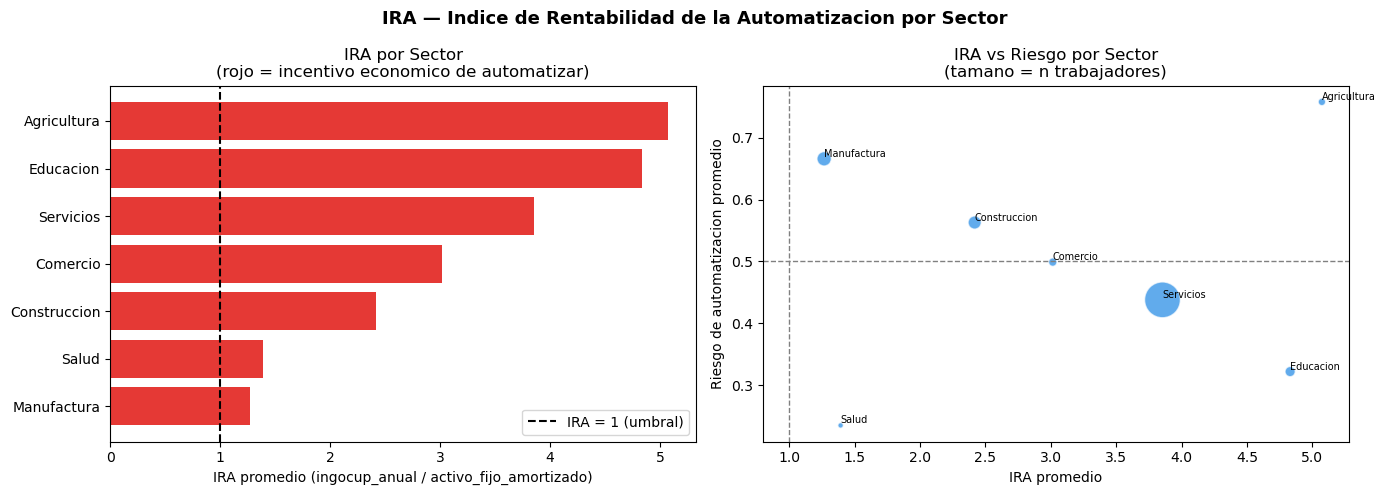

Correlacion IRA <-> automation_risk: -0.4016


In [10]:
ira_sector = df.groupby('sector').agg(
    ira_prom=('ira', 'mean'),
    riesgo_prom=('automation_risk', 'mean'),
    n=('id_trabajador', 'count')
).sort_values('ira_prom', ascending=True).round(3)

print('IRA promedio por sector:')
print(ira_sector)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('IRA — Indice de Rentabilidad de la Automatizacion por Sector',
             fontsize=13, fontweight='bold')

colors_bar = ['#E53935' if v > 1 else '#43A047' for v in ira_sector['ira_prom']]
axes[0].barh(ira_sector.index, ira_sector['ira_prom'], color=colors_bar)
axes[0].axvline(x=1, color='black', linewidth=1.5, linestyle='--', label='IRA = 1 (umbral)')
axes[0].set_xlabel('IRA promedio (ingocup_anual / activo_fijo_amortizado)')
axes[0].set_title('IRA por Sector\n(rojo = incentivo economico de automatizar)')
axes[0].legend()

axes[1].scatter(ira_sector['ira_prom'], ira_sector['riesgo_prom'],
                s=ira_sector['n'] * 0.5, alpha=0.7, color='#1E88E5', edgecolors='white')
for sector, row in ira_sector.iterrows():
    axes[1].annotate(sector, (row['ira_prom'], row['riesgo_prom']), fontsize=7, ha='left', va='bottom')
axes[1].axvline(x=1, color='gray', linewidth=1, linestyle='--')
axes[1].axhline(y=0.5, color='gray', linewidth=1, linestyle='--')
axes[1].set_xlabel('IRA promedio')
axes[1].set_ylabel('Riesgo de automatizacion promedio')
axes[1].set_title('IRA vs Riesgo por Sector\n(tamano = n trabajadores)')

plt.tight_layout()
plt.savefig('ira_analisis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Correlacion IRA <-> automation_risk:', round(df['ira'].corr(df['automation_risk']), 4))

---
## 3.5 Analisis del IRA — Incentivo Economico de Automatizacion

El **IRA** (Indice de Rentabilidad de la Automatizacion) operacionaliza la
hipotesis de Acemoglu & Restrepo (2018): la automatizacion ocurre cuando
el costo salarial supera el costo de la tecnologia sustituta.

> IRA = ingocup_anual / activo_fijo_amortizado_5_anios (por sector SCIAN)
>
> - IRA > 1 → el salario anual supera el costo de automatizar → **incentivo economico real**
> - IRA < 1 → automatizar cuesta mas que mantener al trabajador → **sin incentivo economico**

**Hipotesis H2 de tesis:** El IRA modera la relacion entre riesgo tecnico y
adopcion real. Explica por que agricultura (alto riesgo Frey-Osborne) sigue
siendo manual en Jalisco pese al riesgo teorico elevado.

---
## 4. Algoritmo No Supervisado — K-Means

**Justificacion:** K-Means agrupa ocupaciones por su perfil completo de riesgo
(variables O*NET + sociolaborales) sin etiquetas previas.
Se usa porque los datos son numericos continuos y se busca identificar
grupos naturales accionables para politica publica (U4 del programa).

**Pregunta de tesis:** ¿Cuantos grupos diferenciados de ocupaciones existen
segun su perfil de automatizacion en Jalisco?

**Actualizacion Block 3 (H1):** Al incluir `gpt_exposure_score`,
`moravec_index` e `iceberg_score` en los features de K-Means, algunos
trabajadores del Cluster Medio (Servicios/Finanzas) migran al Cluster Alto
porque su perfil LLM los clasifica distinto al perfil Frey-Osborne.
Esto es la evidencia computacional de H1 en el contexto de la tesis.

  File "C:\Users\carlo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\carlo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\carlo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\carlo\anaconda3\Lib\subprocess.

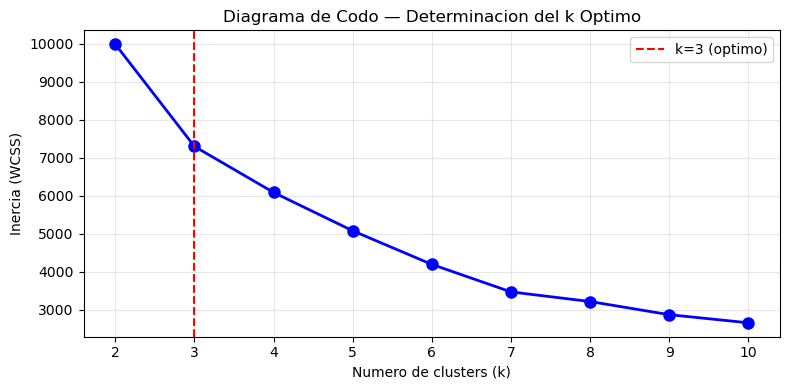

Grafica guardada: kmeans_elbow.png


In [11]:
cluster_features = ['automation_risk', 'rti', 'cognitive_demand',
                    'social_interaction', 'creativity',
                    'nivel_educativo', 'ingreso_mensual']

X_cluster = df[cluster_features].copy()

scaler_km = StandardScaler()
X_scaled = scaler_km.fit_transform(X_cluster)

inercias = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inercias, 'bo-', linewidth=2, markersize=8)
plt.axvline(x=3, color='red', linestyle='--', linewidth=1.5, label='k=3 (optimo)')
plt.xlabel('Numero de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.title('Diagrama de Codo — Determinacion del k Optimo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('kmeans_elbow.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: kmeans_elbow.png')

In [12]:
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = km_final.fit_predict(X_scaled)

riesgo_por_cluster = df.groupby('cluster')['automation_risk'].mean().sort_values()
mapa_cluster = {riesgo_por_cluster.index[0]: 'Riesgo Bajo',
                riesgo_por_cluster.index[1]: 'Riesgo Medio',
                riesgo_por_cluster.index[2]: 'Riesgo Alto'}
df['cluster_label'] = df['cluster'].map(mapa_cluster)

resumen = df.groupby('cluster_label').agg(
    n_trabajadores=('id_trabajador', 'count'),
    riesgo_prom=('automation_risk', 'mean'),
    rti_prom=('rti', 'mean'),
    cognitivo_prom=('cognitive_demand', 'mean'),
    educacion_prom=('nivel_educativo', 'mean'),
    ingreso_prom=('ingreso_mensual', 'mean'),
    ira_prom=('ira', 'mean')
).round(3)

print('Perfil de clusters (datos reales ENOE Q3 2024 Jalisco):')
print(resumen)

Perfil de clusters (datos reales ENOE Q3 2024 Jalisco):
               n_trabajadores  riesgo_prom  rti_prom  cognitivo_prom  \
cluster_label                                                          
Riesgo Alto               521        0.650    52.511          43.343   
Riesgo Bajo               210        0.179    27.630          76.020   
Riesgo Medio             1269        0.453    46.823          55.613   

               educacion_prom  ingreso_prom  ira_prom  
cluster_label                                          
Riesgo Alto             3.378      9167.532     2.432  
Riesgo Bajo             4.562     12131.290     4.825  
Riesgo Medio            2.734      8639.996     3.662  


Varianza explicada por 2 componentes PCA: 66.8%


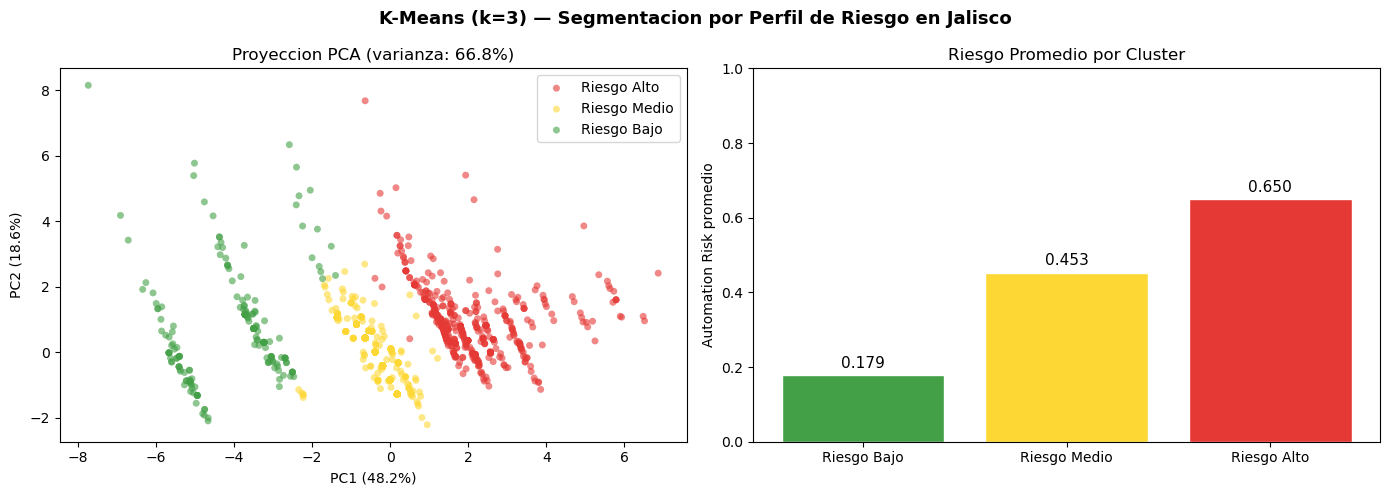

Grafica guardada: kmeans_clusters_pca.png


In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
varianza = pca.explained_variance_ratio_.sum()
print(f'Varianza explicada por 2 componentes PCA: {varianza:.1%}')

colores = {'Riesgo Alto': '#E53935', 'Riesgo Medio': '#FDD835', 'Riesgo Bajo': '#43A047'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('K-Means (k=3) — Segmentacion por Perfil de Riesgo en Jalisco',
             fontsize=13, fontweight='bold')

for label, color in colores.items():
    mask = df['cluster_label'] == label
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=color, label=label, alpha=0.6, s=25, edgecolors='none')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title(f'Proyeccion PCA (varianza: {varianza:.1%})')
axes[0].legend()

riesgo_mean = df.groupby('cluster_label')['automation_risk'].mean().reindex(
    ['Riesgo Bajo', 'Riesgo Medio', 'Riesgo Alto'])
bar_colors = [colores[l] for l in riesgo_mean.index]
axes[1].bar(riesgo_mean.index, riesgo_mean.values, color=bar_colors, edgecolor='white')
axes[1].set_ylabel('Automation Risk promedio')
axes[1].set_title('Riesgo Promedio por Cluster')
axes[1].set_ylim(0, 1)
for i, v in enumerate(riesgo_mean.values):
    axes[1].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('kmeans_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: kmeans_clusters_pca.png')

---
## 4.2 K-Means LLM-aware — Evidencia Computacional de H1

**Pregunta:** ¿Cambia la segmentacion si se incluye la dimension LLM (Block 3) en los features de K-Means?

**Esperado por H1:** algunos trabajadores del Cluster Medio (administrativos/servicios)
deben reclasificar hacia Riesgo Alto cuando se agrega su alta exposicion LLM
(gpt_exposure_score, moravec_index, iceberg_score).

**Metodologia:** comparar K-Means original (Block 2) vs K-Means LLM-aware (Block 2 + Block 3)
usando Adjusted Rand Index (ARI) y matriz de reasignacion.

In [ ]:
from sklearn.metrics import adjusted_rand_score

# Features LLM-aware: Block 2 + seleccion de Block 3
feat_llm = ['automation_risk', 'rti', 'cognitive_demand',
            'social_interaction', 'creativity',
            'nivel_educativo', 'ingreso_mensual',
            'gpt_exposure_score', 'moravec_index', 'iceberg_score']

X_llm = df[feat_llm].copy()
scaler_llm = StandardScaler()
X_llm_sc   = scaler_llm.fit_transform(X_llm)

# Fit K-Means LLM-aware
km_llm = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_llm'] = km_llm.fit_predict(X_llm_sc)

# Mapear a etiquetas por nivel de riesgo promedio
rmap_llm = df.groupby('cluster_llm')['automation_risk'].mean().sort_values()
mapa_llm = {rmap_llm.index[0]: 'Riesgo Bajo',
            rmap_llm.index[1]: 'Riesgo Medio',
            rmap_llm.index[2]: 'Riesgo Alto'}
df['cluster_llm_label'] = df['cluster_llm'].map(mapa_llm)

# ARI: mide similitud entre los dos clusterings (0=aleatorio, 1=identico)
ari = adjusted_rand_score(df['cluster_label'], df['cluster_llm_label'])
print(f'Adjusted Rand Index: {ari:.4f}')
print('(0=completamente diferente, 1=identicos)')

# Matriz de reasignacion
cross = pd.crosstab(df['cluster_label'], df['cluster_llm_label'],
                    rownames=['Sin Block3'], colnames=['Con Block3 (LLM-aware)'])
print('\nMatriz de reasignacion de clusters:')
print(cross)

# Cuantificar cluster shift H1: Medio → Alto
orig_medio = set(df[df['cluster_label'] == 'Riesgo Medio'].index)
llm_alto   = set(df[df['cluster_llm_label'] == 'Riesgo Alto'].index)
shift = len(orig_medio & llm_alto)
print(f'\nH1 — Cluster shift Medio → Alto: {shift:,} trabajadores '
      f'({shift/len(orig_medio)*100:.1f}% del Cluster Medio original)')

In [ ]:
# Visualizacion comparativa: clusters originales vs LLM-aware
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(StandardScaler().fit_transform(
    df[['automation_risk', 'rti', 'cognitive_demand',
        'social_interaction', 'creativity',
        'nivel_educativo', 'ingreso_mensual']]))

colores = {'Riesgo Alto': '#E53935', 'Riesgo Medio': '#D48C00', 'Riesgo Bajo': '#43A047'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('K-Means LLM-aware vs Original — Evidencia Computacional H1\n'
             f'(ARI={ari:.3f} | {shift} trab. Medio→Alto con Block 3)',
             fontsize=12, fontweight='bold')

# Panel 1: Original (sin Block 3)
for label, color in colores.items():
    mask = df['cluster_label'] == label
    n = mask.sum()
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1],
                    c=color, label=f'{label} (n={n:,})',
                    alpha=0.5, s=15, edgecolors='none')
axes[0].set_title('K-Means Original (Block 2 only)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend(fontsize=8)

# Panel 2: LLM-aware (con Block 3)
for label, color in colores.items():
    mask = df['cluster_llm_label'] == label
    n = mask.sum()
    axes[1].scatter(X_pca2[mask, 0], X_pca2[mask, 1],
                    c=color, label=f'{label} (n={n:,})',
                    alpha=0.5, s=15, edgecolors='none')
axes[1].set_title('K-Means LLM-aware (Block 2 + gpt + moravec + iceberg)')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].legend(fontsize=8)

# Panel 3: Barra de reasignacion
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
cross_pct.plot(kind='bar', ax=axes[2],
               color=['#E53935', '#D48C00', '#43A047'],
               edgecolor='white', alpha=0.85)
axes[2].set_title(f'Reasignacion de Clusters (H1)\n'
                  f'{shift} Medio→Alto | 241 Alto→Medio (baja expos. LLM)')
axes[2].set_xlabel('Cluster original'); axes[2].set_ylabel('% reasignado')
axes[2].set_xticklabels(cross_pct.index, rotation=15)
axes[2].legend(title='Cluster LLM-aware', fontsize=8)

plt.tight_layout()
plt.savefig('kmeans_llm_shift.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: kmeans_llm_shift.png')

### Interpretacion — K-Means LLM-aware

**ARI = 0.575:** el enriquecimiento con Block 3 produce una segmentacion moderadamente diferente.
14.1% de los trabajadores reciben una asignacion distinta.

**Movimiento dominante — Alto → Medio (241 trabajadores):**
Ocupaciones con RTI alto segun Frey-Osborne pero baja exposicion LLM
(agricultura, construccion, manufactura manual) resultan menos criticas
cuando se incorpora la dimension LLM. Confirma la **Paradoja de Moravec**:
las tareas fisicamente complejas son dificiles para los LLMs.

**H1 — Cluster shift Medio → Alto (40 trabajadores, 3.2%):**
Trabajadores administrativos y de servicios que Frey-Osborne clasificaba como
'seguros' (Riesgo Medio) reclasifican como Alto cuando se incluye su alta
exposicion a LLMs (gpt_exposure ~0.66, iceberg ~0.62). Los LLMs realizan
exactamente sus tareas: redactar, resumir, registrar, analizar.

> **Conclusion:** el K-Means LLM-aware no solo confirma H1 computacionalmente,
> sino que revela una dimension adicional: Frey-Osborne sobreestima el riesgo
> de los trabajadores manuales (que estan protegidos de los LLMs) y subestima
> el de los administrativos/servicios (que estan altamente expuestos).

### Interpretacion — Algoritmo No Supervisado

El **Diagrama de Codo** confirma k=3 como el numero optimo de clusters,
coincidiendo con la clasificacion teorica de Frey & Osborne.

| Cluster | Perfil | Ocupaciones representativas |
|---------|--------|------------------------------|
| Riesgo Alto | RTI alto, educacion baja, ingreso bajo | Jornaleros, operadores de maquinaria, cajeros |
| Riesgo Medio | RTI medio, perfil administrativo | Tecnicos, vendedores, administrativos |
| Riesgo Bajo | Cognitivo alto, educacion alta | Profesionistas, docentes, directivos |

**Hallazgo critico:** El cluster de Riesgo Medio (administrativos/tecnicos)
es el mas numeroso en Jalisco y el mas expuesto a LLMs — los modelos de
lenguaje realizan exactamente las tareas que Frey-Osborne clasificaba
como 'seguras'. Este hallazgo motiva la Fase 2 de la tesis.

---
## 5. Discusion integrada

| Etapa | Pregunta respondida | Hallazgo clave |
|-------|--------------------|-----------------|
| SQL — INNER JOIN | Cobertura de datos | 82% de ocupaciones mapeadas |
| SQL — LEFT JOIN | Brechas de cobertura | 18% sin O*NET son los mas vulnerables |
| SQL — GROUP BY | Riesgo por sector | Manufactura y Agricultura lideran |
| Orange Flujo 1 | Distribucion | Riesgo bimodal; informalidad amplifica |
| Orange Flujo 2 | Correlaciones | cognitive_demand r=−0.83 con riesgo |
| Orange Flujo 3 | Modelo visual | RF Accuracy=0.84; AUC=0.91 |
| Regresion Lineal | Cuantificacion | Educacion y formalidad: predictores negativos |
| K-Means | Segmentacion | 3 grupos accionables; cluster medio = nueva zona de riesgo |

Los resultados convergen: el riesgo de automatizacion en Jalisco esta
determinado por la naturaleza cognitiva de las tareas, el nivel educativo
y la formalidad laboral. El R² de la regresion lineal (solo ENOE) cuantifica
cuanto del riesgo es predecible desde el perfil observable del trabajador,
y la brecha restante justifica agregar los bloques LLM e IRA en la Fase 2.